```{contents}
:local:
:depth: 2
```

# 3.4 Constraints in Data-Driven Optimization

:::{admonition} Draft status: first draft
:class: warning
First draft (2026-10-30), written from the course design notes. Not yet reviewed.
:::

```{admonition} Lectures
:class: tip
This topic accompanies these recorded lessons:

- Module 6, Lesson 6: *Constrained Data-Driven Optimization* (its lecture comes earlier; read here)

The lecture is recorded in Module 6, about one week before the lectures of Topics 3.2 and 3.3. We read it here, after them, because its main example needs the direct-search and global methods of those topics.
```

:::{admonition} Learning Objectives
:class: tip

By the end of this topic, you should be able to:

- Distinguish known (glass-box) from unknown (black-box) constraints, and name the four standard ways of handling constraints in data-driven optimization.
- Formulate a penalty function and explain the flat plateau it creates over an infeasible region.
- Compare eliminating a known equality constraint with penalizing it, and explain why each formulation hides some optima from black-box methods.
- Explain why discrete on/off decisions are the wrong job for derivative-free methods, and name the tools that handle them.
:::

In Topics 3.2 and 3.3 we mostly ignored constraints, since BB1 and BB2 had only bounds, plus a penalty value of 10 where the slack stack's load fell out of range. Real black-box problems almost always have constraints, including purity specifications, safety limits, demands that must be met, and units that can be either on or off. In this topic we will see that the way we write those constraints decides which solutions a black-box method can find, and in many cases this is more important than the choice of method used for the search. Our example is BB3, which is the full electrolyzer MINLP of {doc}`../2-nonlinear_mixed_integer/Topic2.6-Non-convex_Problems_and_Bounding` treated as a black box, and we will look at it across the same range of demands for which Topic 2.6 found the optimal configuration of stacks.

## Known and unknown constraints

In most data-driven problems the objective is the black box, and the constraints (if there are any) fall into two categories. **Known** or **glass-box** constraints have explicit equations which can be written down and given to a solver, like a mass balance, a bound on a flow, or a demand which the outputs must meet. **Unknown** or **black-box** constraints are outputs of the same simulation or experiment as the objective, like a product purity computed by a process simulator or whether the simulation converged at all, so the only way to learn whether a point satisfies them is by evaluating that point. A problem may also have no constraints beyond bounds. In fact, most commercial data-driven solvers are written for exactly that **box-constrained** case, $\min f(x)$ subject to $x^L \le x \le x^U$, so anything more needs a creative reformulation.

The example in the lecture is a process for capturing carbon dioxide from flue gas by adsorption (after Kalyanaraman et al. 2016), where the decisions are the design and operating conditions of the process. In this process the mass and heat balances inside the adsorption columns are partial differential equations which must be solved by a simulator, so the outputs of interest (CO₂ purity, recovery and energy use) are black-box functions, and this means the constraints on purity and recovery are also black-box constraints, although the bounds on the design variables are known.

There are both kinds of constraints in the electrolyzer plant. The demand balance $x_A + x_B + x_C = D$ is a known linear equality and the capacity bounds $0 \le x_i \le 1$ are also known constraints, but the minimum-load rule (any stack with a load below $x_{\min} = 0.1$ is off) and the on-cost it triggers are inside BB3, so the solver can only see the cost coming back from the black box, or a value of 10 when the plan cannot be carried out.

:::{exercise}
:label: ex-t34-kinds

For the oilfield and pharmaceutical tablet case studies of Topic 3.1, list two constraints of each and classify each as known or unknown. Then explain how the classification of the demand balance in BB3 would change if the hydrogen output of each stack were measured, with some error, instead of set by the load.
:::

## Four ways to handle constraints

In the lecture there are four approaches, and a fifth one for known constraints can be found in the literature:

1. **Penalty.** Replace the constrained problem by an unconstrained (or bound-constrained) one whose objective adds a penalty for violation, for example $f(x) + \sum_j \mu_j \max(0, g_j(x))$ with one weight per constraint, or, for an equality, $f(x) + \mu\,|h(x)|$. Any box-constrained method can then be used, at a cost: the weight $\mu$ must be tuned, the objective has been changed, and a poor $\mu$ can move the optimum or make it hard to reach. A related **extreme barrier** returns a fixed large value at every infeasible point, which is what BB2 and BB3 do with their value of 10.
2. **One surrogate per constraint.** Fit a surrogate model to the black-box objective and to each black-box constraint, and solve the resulting NLP or MINLP, $\min \hat f(x)$ subject to $\hat g_j(x) \le 0$ for the black-box constraints, $h(x) \le 0$ for the known ones, and the bounds, with a derivative-based solver. This uses the solver's full machinery, but each surrogate costs data to fit, and small errors in a surrogate can move the boundary of the feasible region.
3. **One surrogate for feasibility.** Combine all the violations into a single measure, or a feasible/infeasible label, and fit one model to it, such as a classifier that predicts the probability that a point is feasible; it enters the optimization as a single constraint. This is cheaper than approach 2, but errors in the predicted feasible region can again exclude the optimum or admit infeasible points, and a complicated feasible region may be hard to describe with one function.
4. **Sample-based methods that respect feasibility.** Direct-search methods can be built to improve the objective while keeping or restoring feasibility, with the same three ingredients as in Topic 3.2: the geometry of the sample set, a mechanism for descent and feasibility, and a step size. The progressive-barrier version of mesh-adaptive direct search (Audet and Dennis 2009) is an example.
5. **Elimination.** A known equality constraint can often be solved for one variable and substituted out. The demand balance gives $x_C = D - x_A - x_B$, which removes one variable and the equality together, and this is what BB2 and BB3 do.

Constraint handling in data-driven optimization is still an open research question, and there are only a few software packages that handle general constraints by default. Approaches 2 and 3 need surrogate models, which we have not built yet, so these will be developed on this same black box in {doc}`Topic3.6-Surrogate-Based_Optimization`. Here we will compare the two approaches that need no model, elimination and penalty, on BB3.

:::{exercise}
:label: ex-t34-penalty-weight

`bb3_penalty` in `_lib/part3a_tools.py` adds $\mu\,|x_A + x_B + x_C - D|$ to the fleet cost. At $D = 1.2$, evaluate it at the optimal loads (0.703, 0, 0.497) and at the under-delivering plan (0.703, 0, 0.447), which is 0.05 short. For which values of $\mu$ is the infeasible plan cheaper than the optimum? Estimate the smallest safe $\mu$ from the stacks' marginal power cost, and explain what goes wrong if $\mu$ is much larger than that.
:::

## BB3 and the penalty plateau

We can first recall how BB3 is set up. The decisions are the loads of stacks A and B, where a load below $x_{\min}$ means that the stack is off, and stack C takes the rest, $x_C = 1.2 - x_A - x_B$, so any plan in which C's load is negative, above 1, or between 0 and $x_{\min}$ is infeasible and returns 10. The known optimum from Topic 2.6 is A + C at loads (0.703, 0.497), with a cost of 2.32181, and the runner-up B + C is only 0.4% worse at 2.33012. The cell below runs the five methods of Topics 3.2 and 3.3 on BB3 with the protocol that we used there, which is 30 random starts or seeds with success defined as ending within $2 \times 10^{-3}$ of the optimum (this is a slightly looser tolerance, but it is still tighter than the gap to the runner-up).

In [1]:
%matplotlib inline
import sys
sys.path.insert(0, '..')
import numpy as np
import matplotlib.pyplot as plt
plt.style.use('../settings/plot_style.mplstyle')
from scipy.optimize import minimize, direct, differential_evolution, dual_annealing, Bounds
from _lib import electrolyzer as el
from _lib.part3a_tools import Counter, compass, bb3_penalty, bb3_reference

FSTAR3, TOL = 2.32181, 2e-3
lo, hi = np.zeros(2), np.ones(2)
rng = np.random.default_rng(0)
ends = {}
for meth in ('Nelder-Mead', 'compass', 'DIRECT', 'diff. evolution', 'dual annealing'):
    hits, nf, vals, pts = 0, [], [], []
    for k in range(1 if meth == 'DIRECT' else 30):
        f = Counter(el.bb3); x0 = lo + rng.random(2) * (hi - lo)
        if meth == 'Nelder-Mead':
            r = minimize(f, x0, method='Nelder-Mead', bounds=Bounds(lo, hi), options={'xatol': 1e-6, 'fatol': 1e-8}); xe, fx = r.x, r.fun
        elif meth == 'compass':
            xe, fx = compass(f, x0, lo, hi)
        elif meth == 'DIRECT':
            r = direct(f, Bounds(lo, hi), maxfun=4000, len_tol=1e-6); xe, fx = r.x, r.fun
            first = np.argmax(np.array(f.history) < FSTAR3 + TOL) + 1
        elif meth == 'diff. evolution':
            r = differential_evolution(f, list(zip(lo, hi)), seed=k, tol=1e-8, polish=False); xe, fx = r.x, r.fun
        else:
            r = dual_annealing(f, list(zip(lo, hi)), seed=k, maxfun=4000); xe, fx = r.x, r.fun
        hits += abs(fx - FSTAR3) < TOL; nf.append(f.n); vals.append(fx); pts.append((x0, xe, fx))
    ends[meth] = pts
    n = len(vals); stuck = sum(v >= el.PENALTY for v in vals)
    print(f"{meth:16s} success {hits:2d}/{n:<2d} median evaluations {int(np.median(nf)):5d}   "
          f"runs ending on the plateau (f = 10): {stuck}")
print(f"DIRECT first within {TOL} of the optimum at evaluation {first}")

Nelder-Mead      success  4/30 median evaluations    89   runs ending on the plateau (f = 10): 13
compass          success  5/30 median evaluations    97   runs ending on the plateau (f = 10): 10
DIRECT           success  1/1  median evaluations  4003   runs ending on the plateau (f = 10): 0


diff. evolution  success 25/30 median evaluations   645   runs ending on the plateau (f = 10): 0


dual annealing   success 30/30 median evaluations  4000   runs ending on the plateau (f = 10): 0
DIRECT first within 0.002 of the optimum at evaluation 79


| Method | Success | Median evaluations | Runs ending at $f = 10$ |
|---|---|---|---|
| Nelder–Mead | 4/30 | 89 | 13 |
| compass | 5/30 | 97 | 10 |
| DIRECT | 1/1 | 4,003 | 0 |
| differential evolution | 25/30 | 645 | 0 |
| dual annealing | 30/30 | 4,000 | 0 |

Most local runs fail, and the last column explains why, since between a third and nearly half of their runs (13 of 30 for Nelder–Mead and 10 of 30 for compass search) end on the **penalty plateau**, where $f = 10$ and the final point is infeasible as well as worse than any feasible plan. The figure below shows the final points of these runs. Infeasible points cover 44% of the square (Topic 3.1), and the black box returns the same number on all of that region, so when a direct-search method starts in this region or steps into the region, every poll point returns 10 and no step can ever be an improvement. Compass search halves the step size until the search stops, and the Nelder–Mead simplex shrinks around the starting point. Because the plateau is flat, it carries no information about which way the feasible region lies; this is the price of the extreme-barrier form of the penalty, and it is the reason why approach 1 above emphasizes a penalty which grows with the violation.

findfont: Failed to find font weight ultralight for Helvetica, now using 300.


findfont: Failed to find font weight ultralight for Helvetica, now using 300.


infeasible fraction of the square: 0.44


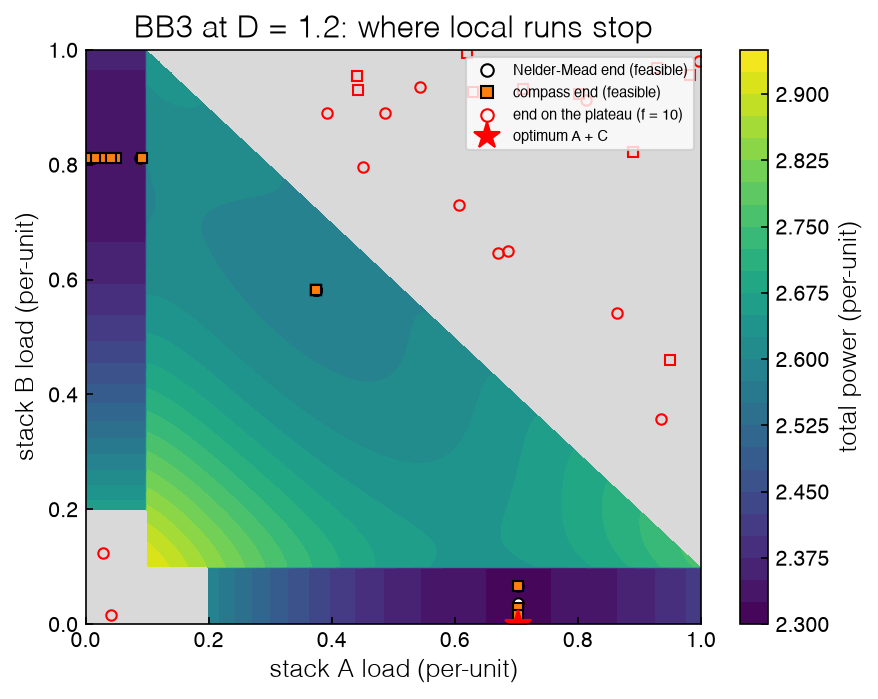

In [2]:
g = np.linspace(0, 1, 401)
F3 = np.array([[el.bb3([a, b]) for a in g] for b in g])
fig, ax = plt.subplots(figsize=(6.2, 5))
ax.contourf(g, g, (F3 >= el.PENALTY).astype(float), levels=[0.5, 1.5], colors=['0.85'])
c = ax.contourf(g, g, np.ma.masked_where(F3 >= el.PENALTY, F3), levels=25, cmap='viridis')
fig.colorbar(c, label='total power (per-unit)')
for meth, mk, col in (('Nelder-Mead', 'o', 'w'), ('compass', 's', 'tab:orange')):
    for x0, xe, fx in ends[meth]:
        ax.plot(*xe, mk, mfc=col if fx < el.PENALTY else 'none', mec='k' if fx < el.PENALTY else 'r', ms=5)
ax.plot([], [], 'o', mfc='w', mec='k', label='Nelder-Mead end (feasible)')
ax.plot([], [], 's', mfc='tab:orange', mec='k', label='compass end (feasible)')
ax.plot([], [], 'o', mfc='none', mec='r', label='end on the plateau (f = 10)')
ax.plot(0.703, 0.0, 'r*', ms=13, label='optimum A + C')
ax.set_xlabel('stack A load (per-unit)'); ax.set_ylabel('stack B load (per-unit)')
ax.set_title('BB3 at D = 1.2: where local runs stop'); ax.legend(fontsize=7, loc='upper right')
print(f"infeasible fraction of the square: {np.mean(F3 >= el.PENALTY):.2f}")

The global methods are not trapped by the plateau, because they do not need a local improvement in order to move. DIRECT finds the optimum within $2 \times 10^{-3}$ at evaluation 79, which is sooner than the $10^{-3}$ first hit on the smooth BB2 (835 evaluations, Topic 3.3), and dual annealing succeeds in all 30 runs. It is surprising that differential evolution does better on the discontinuous BB3 (25 of 30) than on the smooth BB2 (10 of 30), and since we do not have a tested explanation for that, we will leave it as an open question rather than guess.

:::{exercise}
:label: ex-t34-plateau

Replace BB3's flat value of 10 with a graded penalty: for an infeasible plan, return $10 + 10\,v$, where $v$ is the distance by which C's load misses the nearest allowed value (0, or the interval $[x_{\min}, 1]$). Rerun Nelder–Mead and compass search from the same 30 starts. How many runs now end on the plateau, and does the success rate change?
:::

## Elimination versus penalty

BB3 eliminates the demand balance, so the load of stack C is whatever A and B leave, $x_C = D - x_A - x_B$. This keeps the search two-dimensional and ensures that the demand is always met, but it has a hidden cost, because stack C can be off only if A and B carry the demand exactly, $x_A + x_B = D$. In the $(x_A, x_B)$ square that is a line, which is a set of measure zero, so a sampler that draws points from a continuous distribution hits it with probability zero and a direct-search method lands on it only by luck. If the optimum turns C off, no method can find it.

The alternative is to penalize the demand balance instead. In `bb3_penalty` all three loads are decisions and each one that is below $x_{\min}$ is off, and the cost is the fleet's cost plus $\mu\,|x_A + x_B + x_C - D|$ with $\mu = 10$. Now "C off" is a whole face of the cube $x_C < x_{\min}$ that samplers can reach without trouble, and the price that we pay is a third dimension and a demand that is only met approximately, through the penalty.

Topic 2.6 found that the best configuration changes with demand: it is C alone at $D = 0.6$, B alone at 0.9, A + C at 1.2, B + C at 1.5, and A + B at 1.8, and two of these (B and A + B) turn C off. The cell below runs four methods on both formulations at each demand, using 20 random starts for Nelder–Mead and compass search, 20 seeds for differential evolution (with default settings), and one run of DIRECT, where success means that the run ends within $2 \times 10^{-3}$ of the true optimum. (The true optimum at each demand is computed by brute force over the seven on/off configurations as a check value, and Topic 2.6 obtains the same numbers with branch-and-bound.)

In [3]:
OPT = {0.6: 'C', 0.9: 'B', 1.2: 'A+C', 1.5: 'B+C', 1.8: 'A+B'}
METHODS = ('Nelder-Mead', 'compass', 'DIRECT', 'diff. evolution')
results, frac = {}, {}
for D, cfg in OPT.items():
    fstar, cfg_check = bb3_reference(D)
    assert cfg_check == cfg
    for form, f, dim in (('eliminate', lambda x: el.bb3(x, D), 2), ('penalty', lambda x: bb3_penalty(x, D), 3)):
        rng = np.random.default_rng(0)
        for meth in METHODS:
            runs = 1 if meth == 'DIRECT' else 20; hits = 0
            for k in range(runs):
                c = Counter(f); x0 = rng.random(dim); lo, hi = np.zeros(dim), np.ones(dim)
                if meth == 'Nelder-Mead': fx = minimize(c, x0, method='Nelder-Mead', bounds=Bounds(lo, hi)).fun
                elif meth == 'compass': fx = compass(c, x0, lo, hi)[1]
                elif meth == 'DIRECT': fx = direct(c, Bounds(lo, hi), maxfun=4000).fun
                else: fx = differential_evolution(c, list(zip(lo, hi)), seed=k, polish=False).fun
                hits += fx < fstar + 2e-3
            results[(D, form, meth)] = f"{hits}/{runs}"
            frac[(D, form, meth)] = hits / runs
        print(f"D = {D} ({cfg:3s}, optimum {fstar:.4f}) {form:9s}: " +
              "  ".join(f"{m} {results[(D, form, m)]}" for m in METHODS))

D = 0.6 (C  , optimum 1.1566) eliminate: Nelder-Mead 2/20  compass 1/20  DIRECT 1/1  diff. evolution 19/20


D = 0.6 (C  , optimum 1.1566) penalty  : Nelder-Mead 3/20  compass 7/20  DIRECT 0/1  diff. evolution 8/20
D = 0.9 (B  , optimum 1.6824) eliminate: Nelder-Mead 0/20  compass 0/20  DIRECT 0/1  diff. evolution 0/20


D = 0.9 (B  , optimum 1.6824) penalty  : Nelder-Mead 0/20  compass 2/20  DIRECT 1/1  diff. evolution 9/20
D = 1.2 (A+C, optimum 2.3218) eliminate: Nelder-Mead 2/20  compass 5/20  DIRECT 1/1  diff. evolution 19/20


D = 1.2 (A+C, optimum 2.3218) penalty  : Nelder-Mead 1/20  compass 0/20  DIRECT 0/1  diff. evolution 4/20
D = 1.5 (B+C, optimum 2.8278) eliminate: Nelder-Mead 0/20  compass 2/20  DIRECT 1/1  diff. evolution 13/20


D = 1.5 (B+C, optimum 2.8278) penalty  : Nelder-Mead 2/20  compass 1/20  DIRECT 1/1  diff. evolution 8/20
D = 1.8 (A+B, optimum 3.3733) eliminate: Nelder-Mead 0/20  compass 0/20  DIRECT 0/1  diff. evolution 0/20


D = 1.8 (A+B, optimum 3.3733) penalty  : Nelder-Mead 3/20  compass 2/20  DIRECT 0/1  diff. evolution 5/20


| $D$ | Optimum | Formulation | Nelder–Mead | compass | DIRECT | diff. evolution |
|---|---|---|---|---|---|---|
| 0.6 | C | eliminate | 2/20 | 1/20 | 1/1 | 19/20 |
| | | penalty | 3/20 | 7/20 | 0/1 | 8/20 |
| 0.9 | B (C off) | eliminate | **0/20** | **0/20** | **0/1** | **0/20** |
| | | penalty | 0/20 | 2/20 | 1/1 | 9/20 |
| 1.2 | A + C | eliminate | 2/20 | 5/20 | 1/1 | 19/20 |
| | | penalty | 1/20 | 0/20 | 0/1 | 4/20 |
| 1.5 | B + C | eliminate | 0/20 | 2/20 | 1/1 | 13/20 |
| | | penalty | 2/20 | 1/20 | 1/1 | 8/20 |
| 1.8 | A + B (C off) | eliminate | **0/20** | **0/20** | **0/1** | **0/20** |
| | | penalty | 3/20 | 2/20 | 0/1 | 5/20 |

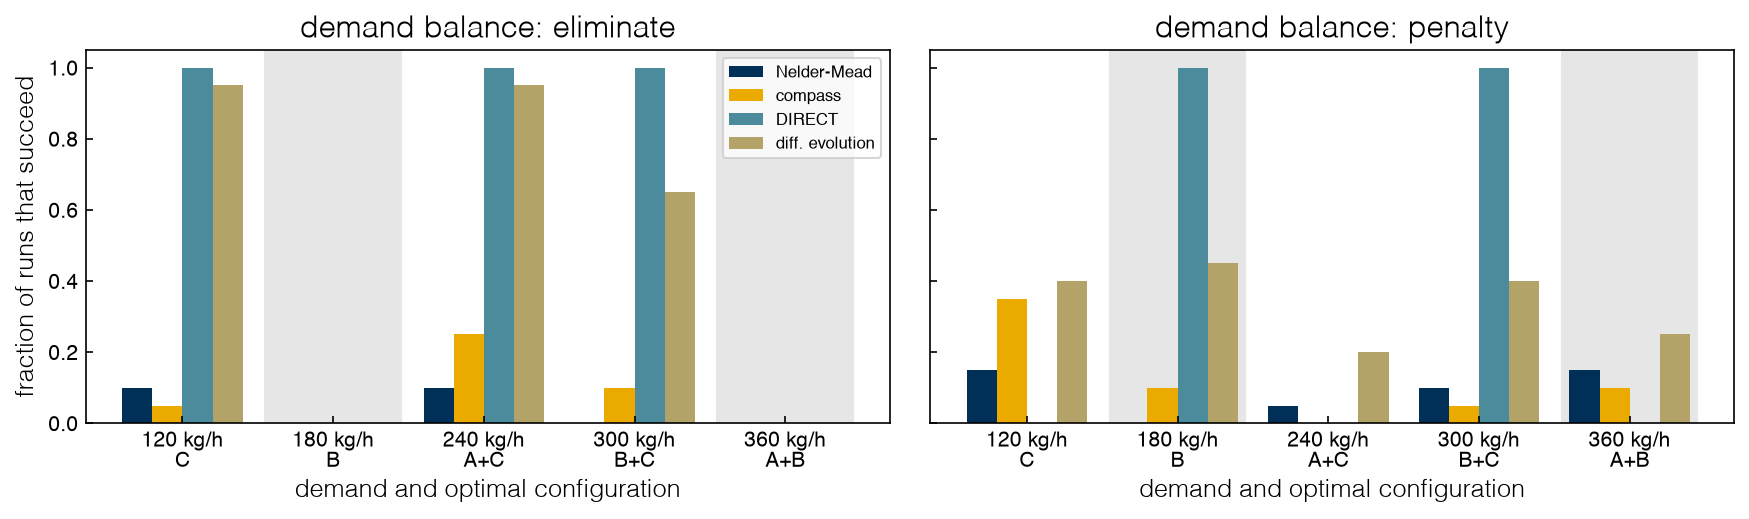

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
w = 0.2
for a, form in zip(ax, ('eliminate', 'penalty')):
    for j, meth in enumerate(METHODS):
        vals = [frac[(D, form, meth)] for D in OPT]
        a.bar(np.arange(5) + (j - 1.5) * w, vals, w, label=meth)
    a.set_xticks(np.arange(5)); a.set_xticklabels([f"{el.to_kg_h(D):.0f} kg/h\n{c}" for D, c in OPT.items()])
    a.set_title(f'demand balance: {form}'); a.set_xlabel('demand and optimal configuration')
    for i, c in enumerate(OPT.values()):
        if 'C' not in c: a.axvspan(i - 0.45, i + 0.45, color='0.9', zorder=0)
ax[0].set_ylabel('fraction of runs that succeed'); ax[0].legend(fontsize=8)
plt.tight_layout()

The shaded columns are the two demands where the optimum turns C off. Under elimination, every method fails in every run at these demands, and this includes DIRECT and differential evolution, with 0 of 20, 0 of 20, 0 of 1, and 0 of 20 successes at both $D = 0.9$ and $D = 1.8$. The choice of method does not matter here, because the optimum lies on a line which is unreachable in this formulation. Where C stays on, elimination works well for the global methods, since DIRECT succeeds at all three of those demands and differential evolution succeeds in 13 to 19 of 20 runs.

Penalizing the demand balance opens the shaded columns, so differential evolution now succeeds in 9 and 5 of 20 runs, DIRECT succeeds at $D = 0.9$, and the local methods succeed in a few runs. However, it costs reliability at all of the other demands: at $D = 1.2$ differential evolution falls from 19 to 4 of 20 and DIRECT goes from success to failure, and at $D = 0.6$ they fall from 19 to 8 and from success to failure. The extra dimension and the kink of the penalty along the demand surface make the search harder at every demand.

**Neither formulation is safe.** With elimination we keep the demand exact and the search space small, but some optima become invisible, whereas with the penalty those optima are visible again but the others become harder to find. A black-box method can only find solutions which are reachable in the formulation, so we need to think of the formulation as part of the method. This is the same lesson as in the optimization fundamentals topics, where the way a problem was written decided its class and its solver, but now we are seeing it from the other side, since here the way the problem is written decides which answers a sampler can see.

:::{exercise}
:label: ex-t34-sweep

Rerun the sweep for differential evolution only, with the penalty weight $\mu$ = 1, 3, 10 and 30 in `bb3_penalty`. Plot the success rate at each demand for each $\mu$. Is there a single $\mu$ that does well at all five demands? Then try a hybrid: eliminate the demand balance but snap C's load to zero whenever $|x_A + x_B - D| < 0.01$. Which demands does it fix, and what does it cost?
:::

## On/off decisions are the wrong job

Behind the elimination failure is a discrete decision, since whether each stack is on or off is a binary choice and the three stacks have seven non-empty on/off configurations. In BB3 these binaries are hidden inside continuous loads, where a load below $x_{\min}$ means the stack is off, so a derivative-free method has to discover a discrete structure through a continuous search. That structure shows up as jumps, plateaus and measure-zero lines, which are exactly the features which defeat local steps, sampling and smooth models.

This is the wrong job for derivative-free methods. The mixed-integer topics already gave us the right tool for it, since branch-and-bound ({doc}`../2-nonlinear_mixed_integer/Topic2.5-Branch_and_Bound`) branches on the binaries directly and bounds each branch, and spatial branch-and-bound (Topic 2.6) proved the optimal configuration at every demand of the sweep, so when a problem has only a few integer decisions and its equations are available, branch-and-bound is the method to use. When the continuous part is a black box and the discrete part is small, the practical fix is to enumerate the configurations and run a continuous black-box method within each one (here this is only seven searches). When neither of these is possible, the remaining option is a surrogate which represents the discrete decisions explicitly (for instance by one-hot encoding the configuration) inside a mixed-integer optimization, and this is the subject of the mixed-integer surrogate example in Topic 3.6.

The two model-based approaches to constraints will also wait for Topic 3.6, where a surrogate per black-box constraint (approach 2) and a classifier that predicts feasibility (approach 3) are both demonstrated on BB3. We will see there that the feasibility classifier needs some care, since a model that is trained only on feasible points extrapolates optimistically into the infeasible region.

:::{exercise}
:label: ex-t34-onoff

At $D = 0.9$, write a black box for each of the seven on/off configurations in which only the "on" stacks have loads and the last on stack takes the rest. For which configurations is the search space empty, a single point, a segment, or a triangle? Without running anything, explain which configuration a DIRECT run on BB3 with elimination can never reach, and why enumeration over configurations fixes it.
:::

## Summary

- Constraints are known (glass-box: explicit equations, like the demand balance) or unknown (black-box: outputs of the simulation, like the minimum-load rule inside BB3).
- Four standard approaches handle them: penalty, a surrogate per constraint, a surrogate for feasibility, and feasibility-preserving sample-based methods. Known equalities can also be eliminated.
- A flat penalty over an infeasible region is a plateau that gives direct search no direction. On BB3 at $D = 1.2$, 13 of 30 Nelder–Mead runs and 10 of 30 compass runs stop on it; the local methods succeed 4 and 5 times in 30, while dual annealing succeeds 30 times and differential evolution 25.
- Eliminating the demand balance makes "C off" a measure-zero line: at $D = 0.9$ and $1.8$, where the optimum turns C off, every method fails in every run. Penalizing the balance makes those optima reachable but costs reliability at the other demands. Neither formulation is safe; the formulation decides what a black-box method can find.
- Discrete on/off decisions are the wrong job for derivative-free methods. Branch-and-bound (Topics 2.5 and 2.6) owns them; enumeration is the practical fix for a few configurations; mixed-integer surrogates and constraint surrogates follow in Topic 3.6.

## Additional Reading

- Conn, A. R., Scheinberg, K., and Vicente, L. N. (2009). *Introduction to Derivative-Free Optimization*. SIAM. Chapter 13 surveys constrained derivative-free optimization.
- Audet, C., and Dennis, J. E., Jr. (2009). A progressive barrier for derivative-free nonlinear programming. *SIAM Journal on Optimization*, 20, 445–472.
- Boukouvala, F., Misener, R., and Floudas, C. A. (2016). Global optimization advances in mixed-integer nonlinear programming, MINLP, and constrained derivative-free optimization, CDFO. *European Journal of Operational Research*, 252, 701–727.
- Kalyanaraman, J., Kawajiri, Y., Lively, R. P., and Realff, M. J. (2016). Uncertainty quantification via Bayesian inference using sequential Monte Carlo methods for CO₂ adsorption process. *AIChE Journal*, 62(9), 3352–3368. The source of the lecture's CO₂ adsorption-process example.
- Forrester, A. I. J., Sóbester, A., and Keane, A. J. (2008). *Engineering Design via Surrogate Modelling: A Practical Guide*. Wiley.
- Audet, C., and Hare, W. (2017). *Derivative-Free and Blackbox Optimization*. Springer.